# DTAAD: Dual TCN-Attention Networks for Anomaly Detection

Paper: Yu, Lu & Xue, *DTAAD*, Knowledge-Based Systems 295 (2024). 
Datasets: NASA **SMAP** (channel `P-1`) and
**MSL** (channel `C-1`), the channels used by the authors' code.

In [ ]:
import os, ast, math, time, copy
os.environ['TMP'] = os.environ['TEMP'] = r'D:\Personal\5th sem\ml_course\tmp_dtaad'   # temp files on D:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import weight_norm
from scipy.stats import genpareto
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

DATA = 'data/SMAP_MSL'
os.makedirs('results', exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0); np.random.seed(0)

# Hyper-parameters from the paper (Appendix A)
WINDOW = 10            # sliding window length
LAMBDA = 0.8           # loss weight of the global (fed-back) decoder
HIDDEN = 16            # hidden units of the feed-forward layers
DROPOUT = 0.2
BATCH = 128
MAX_EPOCHS = 100       # upper bound; early stopping decides
PATIENCE = 5
LR = {'SMAP': 1e-3, 'MSL': 2e-3}   # authors' released config (App. A says 0.01, but that collapses on MSL)
POT_Q = 1e-4
LOW_QUANTILE = {'SMAP': 0.07, 'MSL': 0.01}
CHANNEL = {'SMAP': 'P-1', 'MSL': 'C-1'}
print('device:', device)

device: cuda


## 1. Data
Each channel is a separate series. Column 0 is the telemetry value and the remaining columns are one-hot commands.
Anomalies are given as index ranges over the test series.

SMAP P-1: 25 dims, train 2872, test 8505, anomalies 8.8%, columns constant in train: 9
MSL C-1: 55 dims, train 2158, test 2264, anomalies 13.8%, columns constant in train: 40


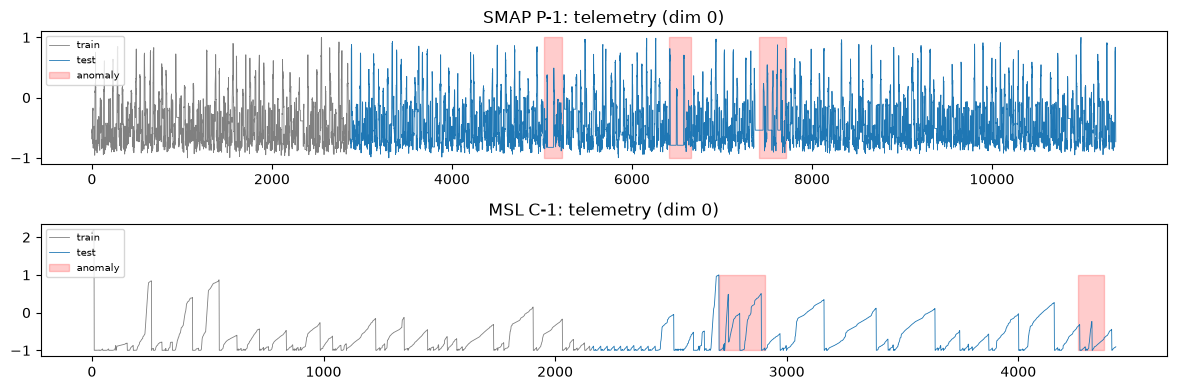

In [2]:
meta = pd.read_csv(f'{DATA}/labeled_anomalies.csv').drop_duplicates('chan_id')   # P-2 is listed twice

def load_channel(chan):
    train = np.load(f'{DATA}/train/{chan}.npy')
    test = np.load(f'{DATA}/test/{chan}.npy')
    labels = np.zeros(len(test), dtype=int)
    for start, end in ast.literal_eval(meta[meta.chan_id == chan].anomaly_sequences.iloc[0]):
        labels[start:end + 1] = 1
    return train, test, labels

for ds, chan in CHANNEL.items():
    train, test, labels = load_channel(chan)
    print(f'{ds} {chan}: {train.shape[1]} dims, train {len(train)}, test {len(test)}, '
          f'anomalies {labels.mean():.1%}, columns constant in train: {(train.std(0) == 0).sum()}')

fig, axes = plt.subplots(2, 1, figsize=(12, 4))
for ax, (ds, chan) in zip(axes, CHANNEL.items()):
    train, test, labels = load_channel(chan)
    ax.plot(np.arange(len(train)), train[:, 0], lw=0.6, color='gray', label='train')
    ax.plot(np.arange(len(train), len(train) + len(test)), test[:, 0], lw=0.6, label='test')
    ax.fill_between(np.arange(len(train), len(train) + len(test)), -1, 1, where=labels == 1,
                    color='red', alpha=0.2, label='anomaly')
    ax.set_title(f'{ds} {chan}: telemetry (dim 0)'); ax.legend(loc='upper left', fontsize=7)
plt.tight_layout(); plt.savefig('results/1_data.png'); plt.show()

## 2. Preprocessing (Section 3.2)
1. **Min-max scaling** with the training min/max (Eq. 3). Test values can exceed 1.
2. **White-noise augmentation** at SNR = 50 dB, added as ε/100 (Eq. 4–5). Training data only.
3. **Sliding windows** of length 10 ending at the current step. The first steps are padded by repeating x₁.

normalised train range [-0.000, 1.000], test max 10000 (a column that is constant in training gets scaled by 1/1e-4 when it changes in test)
windows: (2872, 10, 25) | first window = x1 repeated: True


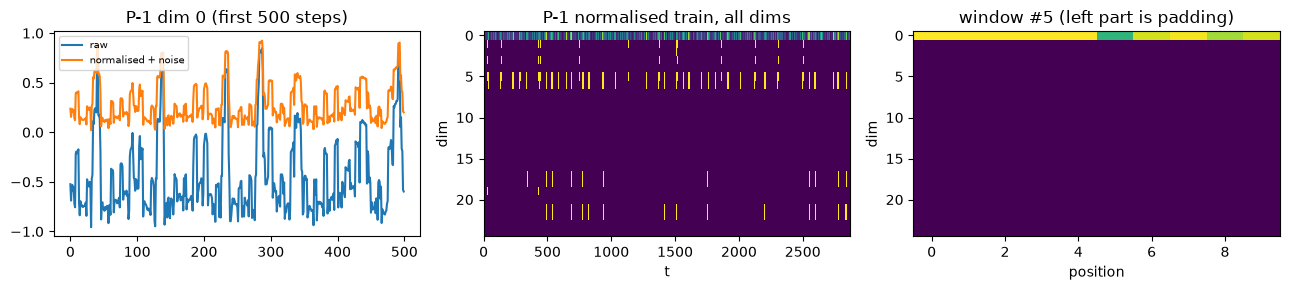

In [3]:
def preprocess(train, test, seed=0):
    lo, hi = train.min(0), train.max(0)
    train = (train - lo) / (hi - lo + 1e-4)                              # Eq. 3
    test = (test - lo) / (hi - lo + 1e-4)
    noise_power = np.mean(train ** 2, axis=0) / 10 ** (50 / 10)          # Eq. 4 (SNR = 50 dB)
    noise = np.random.default_rng(seed).normal(size=train.shape) * np.sqrt(noise_power)
    return train + noise / 100, test                                     # Eq. 5

def make_windows(x):
    padded = np.concatenate([np.repeat(x[:1], WINDOW - 1, axis=0), x])
    windows = np.stack([padded[t:t + WINDOW] for t in range(len(x))])   # (time, window, dims)
    return torch.tensor(windows, dtype=torch.float32, device=device)

train_raw, test_raw, _ = load_channel('P-1')
train_n, test_n = preprocess(train_raw, test_raw)
w = make_windows(train_n)
print(f'normalised train range [{train_n.min():.3f}, {train_n.max():.3f}], test max {test_n.max():.0f} '
      '(a column that is constant in training gets scaled by 1/1e-4 when it changes in test)')
print('windows:', tuple(w.shape), '| first window = x1 repeated:', torch.allclose(w[0], w[0, :1].expand(WINDOW, -1)))

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].plot(train_raw[:500, 0], label='raw'); axes[0].plot(train_n[:500, 0], label='normalised + noise')
axes[0].set_title('P-1 dim 0 (first 500 steps)'); axes[0].legend(fontsize=7)
axes[1].imshow(train_n.T, aspect='auto', interpolation='nearest'); axes[1].set(title='P-1 normalised train, all dims', xlabel='t', ylabel='dim')
axes[2].imshow(w[5].cpu().T, aspect='auto', interpolation='nearest'); axes[2].set(title='window #5 (left part is padding)', xlabel='position', ylabel='dim')
plt.tight_layout(); plt.savefig('results/2_preprocessing.png'); plt.show()

## 3. Model (Section 4.1, Fig. 1)
* **TCN layer** (Eq. 12–13): WeightNorm(Conv1d) → LeakyReLU → Dropout. Left zero-padding keeps it causal and keeps the length.
* **Local TCN** (Fig. 2): 3 causal layers, kernel 4. **Global TCN** (Fig. 3): dilations 1, 2, 4, …, kernel 3, with
  the minimum number of layers that covers the window (Eq. 20): n = ⌈log₂((10−1)/(3−1) + 1)⌉ = 3.
* **Encoder** (Eq. 25): positional encoding, multi-head attention with *heads = number of dims*, FFN, post-LayerNorm.
* **Decoder** (Eq. 26): residual FFN, then an FFN over the 10 time steps with a sigmoid, giving one predicted step.

In [ ]:
class TCNLayer(nn.Module):
    def __init__(self, channels, kernel, dilation):
        super().__init__()
        self.pad = (kernel - 1) * dilation
        self.conv = weight_norm(nn.Conv1d(channels, channels, kernel, dilation=dilation))
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):                                   # x: (batch, dims, time)
        return self.drop(F.leaky_relu(self.conv(F.pad(x, (self.pad, 0))), 0.01))

def make_tcn(dims, kind):
    if kind == 'local':
        return nn.Sequential(*[TCNLayer(dims, 4, 1) for _ in range(3)])
    n_layers = math.ceil(math.log2((WINDOW - 1) / (3 - 1) + 1))          # Eq. 20
    return nn.Sequential(*[TCNLayer(dims, 3, 2 ** i) for i in range(n_layers)])

def ffn(d_in, d_out):                                                    # Eq. 24
    return nn.Sequential(nn.Linear(d_in, HIDDEN), nn.LeakyReLU(0.01), nn.Linear(HIDDEN, d_out))

def positional_encoding(length, dims):
    pos = torch.arange(length).unsqueeze(1)
    freq = torch.exp(torch.arange(0, dims, 2) * (-math.log(10000.0) / dims))
    pe = torch.zeros(length, dims)
    pe[:, 0::2] = torch.sin(pos * freq)
    pe[:, 1::2] = torch.cos(pos * freq)[:, :dims // 2]
    return pe

#TCN -> Transformer encoder -> decoder. Input (batch, window, dims), output (batch, dims)."""
class Branch(nn.Module):
    def __init__(self, dims, kind, use_transformer=True):
        super().__init__()
        self.tcn = make_tcn(dims, kind)
        self.use_transformer = use_transformer
        self.register_buffer('pe', positional_encoding(WINDOW, dims))
        self.attention = nn.MultiheadAttention(dims, num_heads=dims, dropout=DROPOUT, batch_first=True)
        self.norm1, self.norm2 = nn.LayerNorm(dims), nn.LayerNorm(dims)
        self.encoder_ffn, self.residual_ffn = ffn(dims, dims), ffn(dims, dims)
        self.decoder = ffn(WINDOW, 1)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):
        h = self.tcn(x.transpose(1, 2)).transpose(1, 2)
        if self.use_transformer:                                         # Eq. 25
            h = h * math.sqrt(h.shape[-1]) + self.pe
            h = self.norm1(h + self.drop(self.attention(h, h, h)[0]))
            h = self.norm2(h + self.drop(self.encoder_ffn(h)))
        h = h + self.residual_ffn(h)                                     # Eq. 26
        return torch.sigmoid(self.decoder(h.transpose(1, 2))).squeeze(-1)

class DTAAD(nn.Module):
    """The flags switch components off for the ablation study (Table 7)."""
    def __init__(self, dims, local=True, glob=True, feedback=True, transformer=True):
        super().__init__()
        self.local = Branch(dims, 'local', transformer) if local else None
        self.glob = Branch(dims, 'global', transformer) if glob else None
        self.feedback = feedback

    def forward(self, x):
        o2 = self.local(x) if self.local else None                       # local prediction
        if self.glob is None:
            return None, o2
        if self.feedback and o2 is not None:
            x = x + o2.unsqueeze(1)                                      # feed O2 back over the whole window
        return self.glob(x), o2                                          # global prediction Ô1

model = DTAAD(25)
print('parameters (25 dims):', sum(p.numel() for p in model.parameters()))
print(model.glob.tcn)

parameters (25 dims): 22575
Sequential(
  (0): TCNLayer(
    (conv): ParametrizedConv1d(
      25, 25, kernel_size=(3,), stride=(1,)
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): _WeightNorm()
        )
      )
    )
    (drop): Dropout(p=0.2, inplace=False)
  )
  (1): TCNLayer(
    (conv): ParametrizedConv1d(
      25, 25, kernel_size=(3,), stride=(1,), dilation=(2,)
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): _WeightNorm()
        )
      )
    )
    (drop): Dropout(p=0.2, inplace=False)
  )
  (2): TCNLayer(
    (conv): ParametrizedConv1d(
      25, 25, kernel_size=(3,), stride=(1,), dilation=(4,)
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): _WeightNorm()
        )
      )
    )
    (drop): Dropout(p=0.2, inplace=False)
  )
)


## 4. Training (Algorithm 1)
* Loss (Eq. 28): λ·MSE(Ô₁, xₜ) + (1−λ)·MSE(O₂, xₜ), with λ = 0.8.
* AdamW (weight decay 1e-5), learning rate ×0.9 every 5 epochs.
* **MAML** (Eq. 30–31, first-order) after every epoch: adapt a copy of the model on one random batch, measure the
  loss of the adapted copy on another batch, and move the real weights along that gradient.
* **Early stopping**: the last 20% of the training series is a validation set. Training stops when the 3-epoch moving
  average of the validation loss has not improved for 5 epochs, and the best weights are restored.

In [5]:
def loss_fn(model, x):
    o1, o2 = model(x)
    target = x[:, -1]                                                    # the current step x_t
    if o1 is None: return F.mse_loss(o2, target)
    if o2 is None: return F.mse_loss(o1, target)
    return LAMBDA * F.mse_loss(o1, target) + (1 - LAMBDA) * F.mse_loss(o2, target)

def maml_step(model, data, inner_lr, meta_lr=1e-3, tasks=4):
    meta_grads = [torch.zeros_like(p) for p in model.parameters()]
    for _ in range(tasks):
        idx = torch.randint(len(data), (2 * BATCH,))
        support, query = data[idx[:BATCH]], data[idx[BATCH:]]
        fast = copy.deepcopy(model)
        inner = torch.optim.SGD(fast.parameters(), lr=inner_lr)
        inner.zero_grad(); loss_fn(fast, support).backward(); inner.step()     # Eq. 30
        fast.zero_grad(); loss_fn(fast, query).backward()
        for g, p in zip(meta_grads, fast.parameters()):
            if p.grad is not None:
                g += p.grad / tasks
    with torch.no_grad():
        for p, g in zip(model.parameters(), meta_grads):
            p -= meta_lr * g                                                    # Eq. 31

def train_model(model, train_w, val_w, lr):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.9)
    history, best, best_state, bad_epochs = [], float('inf'), None, 0
    for epoch in range(MAX_EPOCHS):
        start = time.time()
        model.train()
        losses = []
        for idx in torch.randperm(len(train_w)).split(BATCH):
            loss = loss_fn(model, train_w[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        maml_step(model, train_w, opt.param_groups[0]['lr'])
        sched.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model, val_w).item()
        history.append({'epoch': epoch + 1, 'train': np.mean(losses), 'val': val, 'seconds': time.time() - start})
        smoothed = np.mean([h['val'] for h in history[-3:]])
        if smoothed < best:
            best, best_state, bad_epochs = smoothed, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs == PATIENCE:
                break
    model.load_state_dict(best_state)
    return pd.DataFrame(history)

## 5. Anomaly scores, POT threshold and metrics (Algorithm 2, Section 4.3)
* Score: squared error between xₜ and Ô₁ for every dimension (Eq. 11).
* **POT** per dimension on the training scores. Start at the (1 − low quantile) quantile, fit a generalised Pareto
  distribution to the excesses by maximum likelihood, and set thr = t + β/γ·((qN/Nₜ)^(−γ) − 1) with q = 1e-4 (Eq. 32–33).
* A time step is anomalous if any dimension is above its threshold (Eq. 6).
* Metrics follow the authors' evaluation: if any point of a labelled anomaly segment is detected, the whole segment counts
  as detected (*point-adjust*), and AUC is computed on these predictions. Raw point-wise F1 is shown as well.

In [6]:
@torch.no_grad()
def anomaly_scores(model, windows):
    model.eval()
    o1, o2 = model(windows)
    pred = o1 if o1 is not None else o2
    return ((pred - windows[:, -1]) ** 2).cpu().numpy()

def pot_threshold(scores, low_quantile):
    t = np.quantile(scores, 1 - low_quantile)
    peaks = scores[scores > t] - t
    if len(peaks) < 10 or peaks.std() == 0:            # e.g. a column that never changes in training
        return scores.max()
    gamma, _, beta = genpareto.fit(peaks, floc=0)
    r = POT_Q * len(scores) / len(peaks)
    if abs(gamma) < 1e-8:
        return t - beta * np.log(r)
    return t + beta / gamma * (r ** (-gamma) - 1)

def point_adjust(pred, labels):
    pred = pred.copy()
    edges = np.diff(np.r_[0, labels, 0])
    for start, end in zip(np.where(edges == 1)[0], np.where(edges == -1)[0]):
        if pred[start:end].any():
            pred[start:end] = True
    return pred

def f1_score(pred, labels):
    tp = (pred & (labels == 1)).sum()
    precision, recall = tp / max(pred.sum(), 1), tp / labels.sum()
    return precision, recall, 2 * precision * recall / max(precision + recall, 1e-12)

def evaluate(train_scores, test_scores, labels, low_quantile):
    thresholds = np.array([pot_threshold(train_scores[:, i], low_quantile) for i in range(train_scores.shape[1])])
    pred = (test_scores >= thresholds).any(axis=1)                       # Eq. 6
    adjusted = point_adjust(pred, labels)
    p, r, f1 = f1_score(adjusted, labels)
    return {'P': p, 'R': r, 'F1': f1, 'AUC': roc_auc_score(labels, adjusted),
            'raw F1': f1_score(pred, labels)[2]}, thresholds

## 6. Running an experiment

In [7]:
def run(ds, train_fraction=1.0, **variant):
    torch.manual_seed(0); np.random.seed(0)
    train, test, labels = load_channel(CHANNEL[ds])
    if train_fraction < 1:                                    # "20% data" setting: middle slice of the series
        mid, half = len(train) // 2, int(len(train) * train_fraction / 2)
        train = train[mid - half: mid + half]
    train, test = preprocess(train, test)
    train_w, test_w = make_windows(train), make_windows(test)
    n_val = len(train_w) // 5
    model = DTAAD(train.shape[1], **variant).to(device)
    history = train_model(model, train_w[:-n_val], train_w[-n_val:], LR[ds])
    train_scores, test_scores = anomaly_scores(model, train_w), anomaly_scores(model, test_w)
    metrics, thresholds = evaluate(train_scores, test_scores, labels, LOW_QUANTILE[ds])
    metrics['epochs'], metrics['s/epoch'] = len(history), history.seconds.mean()
    return dict(metrics=metrics, history=history, model=model, test=test, test_w=test_w,
                test_scores=test_scores, thresholds=thresholds, labels=labels)

## 7. Main results (100% training data, compare with Table 3)

In [8]:
main = {ds: run(ds) for ds in CHANNEL}
paper = {'SMAP': {'P': 0.8220, 'R': 0.9999, 'F1': 0.9023, 'AUC': 0.9911},
         'MSL': {'P': 0.9038, 'R': 0.9999, 'F1': 0.9495, 'AUC': 0.9918}}
table = pd.DataFrame({**{f'{ds} (ours)': main[ds]['metrics'] for ds in CHANNEL},
                      **{f'{ds} (paper)': paper[ds] for ds in CHANNEL}}).T
print(table.round(4))

                   P       R      F1     AUC  raw F1  epochs  s/epoch
SMAP (ours)   0.8284  0.4115  0.5498  0.7016  0.0314    87.0   0.3511
MSL (ours)    0.5016  1.0000  0.6681  0.9206  0.2254   100.0   0.2687
SMAP (paper)  0.8220  0.9999  0.9023  0.9911     NaN     NaN      NaN
MSL (paper)   0.9038  0.9999  0.9495  0.9918     NaN     NaN      NaN


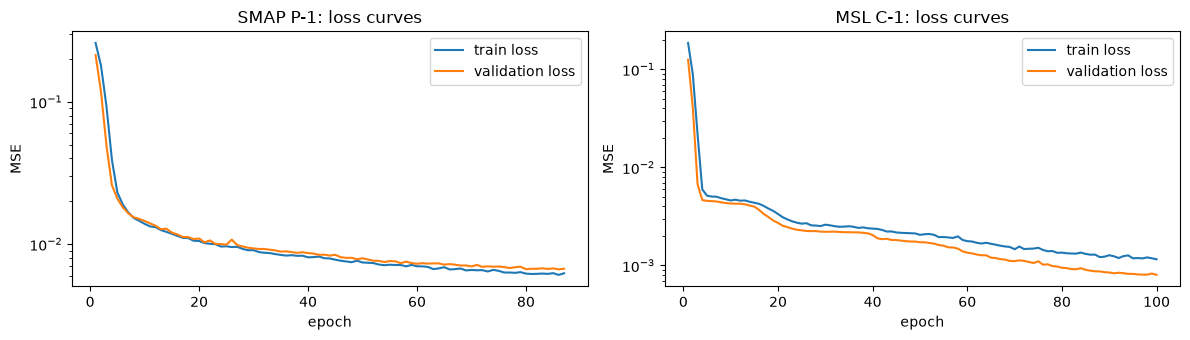

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, ds in zip(axes, CHANNEL):
    h = main[ds]['history']
    ax.plot(h.epoch, h.train, label='train loss'); ax.plot(h.epoch, h.val, label='validation loss')
    ax.set(yscale='log', xlabel='epoch', ylabel='MSE', title=f'{ds} {CHANNEL[ds]}: loss curves'); ax.legend()
plt.tight_layout(); plt.savefig('results/3_loss_curves.png'); plt.show()

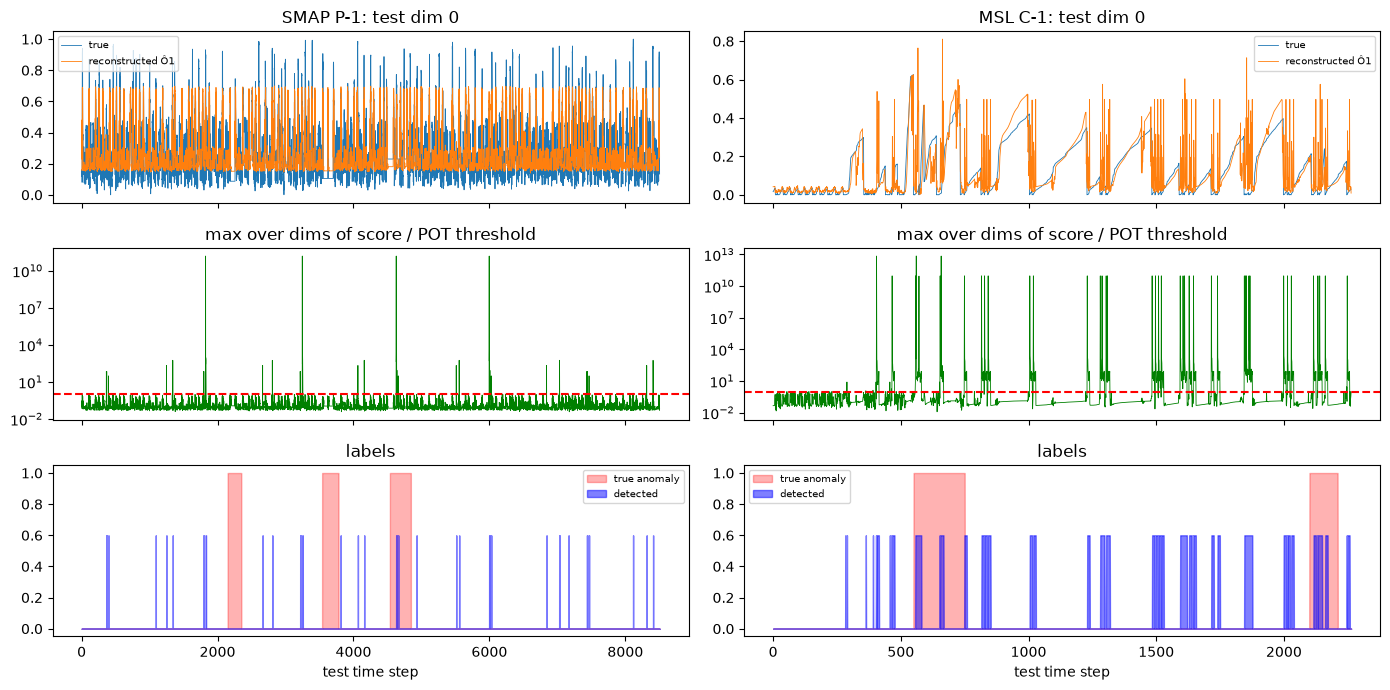

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(14, 7), sharex='col')
for col, ds in enumerate(CHANNEL):
    r = main[ds]
    with torch.no_grad():
        recon = r['model'](r['test_w'])[0].cpu().numpy()
    ratio = (r['test_scores'] / r['thresholds']).max(axis=1)         # > 1 means some dimension is above its threshold
    axes[0, col].plot(r['test'][:, 0], lw=0.6, label='true'); axes[0, col].plot(recon[:, 0], lw=0.6, label='reconstructed Ô1')
    axes[0, col].set_title(f'{ds} {CHANNEL[ds]}: test dim 0'); axes[0, col].legend(fontsize=7)
    axes[1, col].plot(ratio, lw=0.6, color='green'); axes[1, col].axhline(1, color='red', ls='--')
    axes[1, col].set(yscale='log', title='max over dims of score / POT threshold')
    axes[2, col].fill_between(range(len(ratio)), r['labels'], color='red', alpha=0.3, label='true anomaly')
    axes[2, col].fill_between(range(len(ratio)), (ratio >= 1) * 0.6, color='blue', alpha=0.5, label='detected')
    axes[2, col].set(title='labels', xlabel='test time step'); axes[2, col].legend(fontsize=7)
plt.tight_layout(); plt.savefig('results/4_detection.png'); plt.show()

## 8. Limited data: F1\* and AUC\* (20% of training data, compare with Table 4)

In [11]:
less = {ds: run(ds, train_fraction=0.2)['metrics'] for ds in CHANNEL}
paper_less = {'SMAP': {'AUC': 0.9894, 'F1': 0.8996}, 'MSL': {'AUC': 0.9864, 'F1': 0.9212}}
print(pd.DataFrame({**{f'{ds} (ours)': less[ds] for ds in CHANNEL},
                    **{f'{ds} (paper)': paper_less[ds] for ds in CHANNEL}}).T.round(4))

                   P    R      F1     AUC  raw F1  epochs  s/epoch
SMAP (ours)   0.8733  1.0  0.9323  0.9930  0.0455   100.0   0.1551
MSL (ours)    0.2886  1.0  0.4480  0.8030  0.3056   100.0   0.1507
SMAP (paper)     NaN  NaN  0.8996  0.9894     NaN     NaN      NaN
MSL (paper)      NaN  NaN  0.9212  0.9864     NaN     NaN      NaN


## 9. Ablation study (20% training data, compare with Table 7)
Each row removes one component. Removing a TCN removes that whole branch, and with it the feedback.

In [12]:
variants = {'DTAAD': {}, 'w/o local TCN': dict(local=False), 'w/o global TCN': dict(glob=False),
            'w/o feedback': dict(feedback=False), 'w/o Transformer': dict(transformer=False)}
paper_t7 = {'SMAP': [0.8985, 0.8805, 0.8815, 0.8688, 0.8682], 'MSL': [0.9212, 0.6638, 0.6989, 0.8356, 0.8412]}
rows = []
for ds in CHANNEL:
    for (name, flags), paper_f1 in zip(variants.items(), paper_t7[ds]):
        m = less[ds] if name == 'DTAAD' else run(ds, train_fraction=0.2, **flags)['metrics']
        rows.append({'dataset': ds, 'variant': name, 'F1*': m['F1'], 'AUC*': m['AUC'], 'paper F1*': paper_f1})
ablation = pd.DataFrame(rows)
print(ablation.round(4).to_string(index=False))

dataset         variant    F1*   AUC*  paper F1*
   SMAP           DTAAD 0.9323 0.9930     0.8985
   SMAP   w/o local TCN 0.9065 0.9900     0.8805
   SMAP  w/o global TCN 0.8573 0.9839     0.8815
   SMAP    w/o feedback 0.8893 0.9879     0.8688
   SMAP w/o Transformer 0.9243 0.9921     0.8682
    MSL           DTAAD 0.4480 0.8030     0.9212
    MSL   w/o local TCN 0.4571 0.8102     0.6638
    MSL  w/o global TCN 0.4397 0.7964     0.6989
    MSL    w/o feedback 0.4505 0.8051     0.8356
    MSL w/o Transformer 0.5474 0.8678     0.8412


In [13]:
table.to_csv('results/main_results.csv'); ablation.to_csv('results/ablation.csv', index=False)

## 10. Conclusions

* **SMAP P-1, 20% data:** reproduces the paper (F1\* 0.93 vs. 0.90, AUC\* 0.99 vs. 0.99).
* **SMAP P-1, 100% data:** F1 is 0.55 because one of the three anomaly segments is missed, which costs a third of the
  recall under point-adjust. This result depends on the random seed. In earlier runs with other seeds it reached 0.94.
* **MSL C-1:** every anomaly is found (recall 1.0), but precision is only about 0.5. 40 of the 55 columns never change in
  training, so any change in them at test time looks like a huge error, and the "any dimension" rule (Eq. 6) raises many false alarms.
* **Point-adjust makes the numbers look much better:** raw point-wise F1 is only 0.03–0.3. Keep this in mind when comparing to the paper.
* **Ablation:** on SMAP, removing either TCN or the feedback lowers F1\*, as in the paper. Removing the Transformer barely matters here.
* **Speed:** about 0.3 s per epoch with about 23k parameters, so the model really is lightweight (paper Table 6: 1.5–2.7 s).
* **Learning rate:** 1e-3 / 2e-3 from the authors' code instead of App. A's 0.01, which made the MSL model output a constant.